# Track 1 — Q1.6, Q1.8, Q1.9, Q1.10 (qualitative), Q1.11, Q1.12: Reliability, MSE$_\eta$, and the $\lambda$ sweep

**Experiment Plan:** Track 1, Figures 1-C, 1-D, 1-E.

**Experiment questions answered in this notebook:**

> **Q1.6.** Training with the Brier score vs. cross-entropy as the base loss: which base loss,
> when combined with the same soft-ECE calibration penalty, produces better calibration and
> lower MSE$_\eta$?
>
> **Q1.8.** Is there a benefit to overparameterisation in end-to-end calibrated training?
>
> **Q1.9.** Is there a benefit to end-to-end calibration in the overparameterised regime
> specifically — i.e. does adding a calibration penalty help more when $m \gg n$ than when
> $m \approx n$ or $m < n$?
>
> **Q1.10.** Does end-to-end calibration act as an implicit regulariser — does increasing
> $\lambda$'s weight on calibration reduce both bias (MSE$_\eta$) and variance (across seeds)
> simultaneously in the overparameterised regime? **Only the bias half is answered here** (the variance half involving 30-seed is covered in later notebook).
>
> **Q1.11.** Does end-to-end calibration push the model toward the true probability function
> $\eta(x)$, or merely toward nicer-looking reliability diagrams?
>
> **Q1.12.** Is there an optimal $\lambda$ that minimises MSE$_\eta$ without sacrificing sharpness,
> and does this optimum depend on capacity $m$?


This notebook adds $\mathrm{MSE}_\eta$ and top-label ECE, generates reliability and prediction-curve plots, and evaluates a 21-point $\lambda$ grid for the CE and Brier base losses. Results are reported across five paired data/init seeds unless stated otherwise.

## 0. Setup

In [18]:
%%writefile track1_core.py
'''Track 1 core utilities: data-generating process + Legendre basis model.
Copied from Notebook 1 (Setup) so this notebook is self-contained.'''
import numpy as np

TEST_SEED = 999
N_TEST = 50_000
CAPACITY_GRID = [5, 10, 100, 120, 200, 300, 1000]
PRIMARY_CAPACITIES = [10, 100, 1000]
INIT_SCALE = np.sqrt(0.01)


def true_eta(x):
    x = np.asarray(x, dtype=np.float64)
    return 0.1 + 0.8 / (1.0 + np.exp(-4.0 * np.sin(np.pi * x)))


def generate_data(n, seed):
    rng = np.random.default_rng(seed)
    X = rng.uniform(-1.0, 1.0, size=n)
    Y = rng.binomial(1, true_eta(X)).astype(np.float64)
    return X, Y


def get_fixed_test_set():
    return generate_data(n=N_TEST, seed=TEST_SEED)


def legendre_design_matrix(x, m):
    '''Three-term recurrence, O(n*m) -- see Notebook 1 for why this matters at m=1000.'''
    x = np.asarray(x, dtype=np.float64)
    n = x.shape[0]
    Phi = np.empty((n, m + 1), dtype=np.float64)
    Phi[:, 0] = 1.0
    if m >= 1:
        Phi[:, 1] = x
    for k in range(2, m + 1):
        Phi[:, k] = ((2 * k - 1) * x * Phi[:, k - 1] - (k - 1) * Phi[:, k - 2]) / k
    return Phi


def sigmoid(z):
    z = np.clip(z, -500, 500)
    return 1.0 / (1.0 + np.exp(-z))


def init_theta(m, seed):
    rng = np.random.default_rng(seed)
    return rng.normal(loc=0.0, scale=INIT_SCALE, size=m + 1)


def model_predict(theta, Phi):
    return sigmoid(Phi @ theta)

Overwriting track1_core.py


In [19]:
import numpy as np
import torch
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
import track1_core as t1

torch.set_default_dtype(torch.float64)

PALETTE_CAPACITY = {10: "#264653", 100: "#2a9d8f", 1000: "#e76f51"}
plt.rcParams.update({
    "font.family": "STIXGeneral",
    "mathtext.fontset": "stix",
    # "font.family": "serif",
    # "font.serif": ["Computer Modern Roman", "CMU Serif"],
    # "mathtext.fontset": "cm",
    "font.size": 12,
    "axes.labelsize": 13,
    "axes.titlesize": 13,
    "figure.titlesize": 14,
    "figure.titleweight": "bold",
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
    "legend.fontsize": 11,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "figure.dpi": 120,
    "savefig.dpi": 300,
    # "savefig.bbox": "tight",
    # "savefig.pad_inches": 0.05,
    "savefig.format": "pdf"
})

DATA_SEED = 1
INIT_SEED = 42
EPOCHS = 1200
LAMBDA_GRID = [0.0, 0.1, 0.5, 1.0]
SNAPSHOT_EPOCHS = (1, 50, 100, 200, 500, 1200)

## 1. New metrics needed for this notebook

Two metrics that haven't been implemented in earlier notebooks yet:

- **MSE$_\eta$** $= \frac{1}{N}\sum_j (p_\theta(x_j) - \eta(x_j))^2$ — only computable in Track 1,
  since $\eta$ is known exactly here. *"The most important metric in this track... directly
  measures whether end-to-end calibration pushes the model toward the true probability function
  $\eta(x)$, not merely toward nicer-looking reliability diagrams."*
- **ECE (hard-bin)**, standard top-label form: $\sum_b \frac{n_b}{N}|\text{acc}(b) - \text{conf}(b)|$,
  binning by confidence $=\max(p, 1-p) \in [0.5, 1]$ and accuracy against the argmax decision
  rule. This is a different convention from the reliability-style calibration terms
  ($\widehat{C}_{\text{Brier}}$, $\widehat{C}_{\text{CE}}$) built in the previous notebook — those
  bin by raw predicted probability $p$ and compare to the empirical rate; this one bins by
  confidence in the *predicted class* and compares to classification accuracy. Both are legitimate
  and the plan lists both as separate metrics.


In [20]:
def mse_eta(p, x):
    '''MSE_eta = mean((p_theta(x) - eta(x))^2). Only computable in Track 1.'''
    return np.mean((np.asarray(p) - t1.true_eta(x)) ** 2)


def top_label_ece(p, y, B=10):
    '''
    Standard top-label ECE: bin by confidence = max(p, 1-p) in [0.5, 1], compare mean confidence
    to accuracy (correctness of the argmax decision) per bin.
    Returns (ece, bin_confidence_array, bin_accuracy_array) -- the arrays feed reliability diagrams.
    '''
    p = np.asarray(p, dtype=np.float64)
    y = np.asarray(y, dtype=np.float64)
    n = len(p)
    conf = np.maximum(p, 1 - p)
    pred_class = (p >= 0.5).astype(np.float64)
    correct = (pred_class == y).astype(np.float64)
    edges = np.linspace(0.5, 1.0, B + 1)
    bin_idx = np.clip(np.digitize(conf, edges[1:-1], right=False), 0, B - 1)
    ece = 0.0
    bin_conf, bin_acc = [], []
    for b in range(B):
        mask = bin_idx == b
        n_b = mask.sum()
        if n_b == 0:
            bin_conf.append(np.nan)
            bin_acc.append(np.nan)
            continue
        c_b, a_b = conf[mask].mean(), correct[mask].mean()
        ece += (n_b / n) * abs(a_b - c_b)
        bin_conf.append(c_b)
        bin_acc.append(a_b)
    return ece, np.array(bin_conf), np.array(bin_acc)

### Sanity checks

In [21]:
rng = np.random.default_rng(0)
n = 200_000

# MSE_eta: exact predictions -> 0; constant p=0.5 -> clearly positive
x_test = rng.uniform(-1, 1, n)
mse_perfect = mse_eta(t1.true_eta(x_test), x_test)
mse_const = mse_eta(np.full(n, 0.5), x_test)
print(f"MSE_eta, p=eta(x) exactly: {mse_perfect:.2e} (should be ~0)")
print(f"MSE_eta, p=0.5 constant:   {mse_const:.4f} (should be clearly > 0)")
assert mse_perfect < 1e-20 and mse_const > 0.01

# top-label ECE: calibrated vs overconfident
p_cal = rng.uniform(0.05, 0.95, n)
y_cal = rng.binomial(1, p_cal)
ece_cal, _, _ = top_label_ece(p_cal, y_cal, B=10)

p_over = rng.uniform(0.05, 0.95, n)
y_over = rng.binomial(1, p_over)
p_over_reported = np.clip(0.5 + 1.8 * (p_over - 0.5), 0.01, 0.99)
ece_over, _, _ = top_label_ece(p_over_reported, y_over, B=10)

print(f"\nECE, calibrated case:    {ece_cal:.5f}")
print(f"ECE, overconfident case: {ece_over:.5f}")
assert ece_over > ece_cal
print("\nOK: both new metrics behave correctly.")

MSE_eta, p=eta(x) exactly: 0.00e+00 (should be ~0)
MSE_eta, p=0.5 constant:   0.1030 (should be clearly > 0)

ECE, calibrated case:    0.00251
ECE, overconfident case: 0.11692

OK: both new metrics behave correctly.


## 2. Training objective and snapshot-capturing training loop

Same objective as the previous notebook: $\mathcal{L}_\lambda = (1-\lambda)\widehat{\mathcal C}_e^{\text{soft}} + \lambda\widehat{\mathcal E}$,
full-batch GD, $\eta=0.5$, 1200 epochs. This notebook records
predictions at a handful of specific epochs (for Figure 1-C's reliability-diagram snapshots) plus the final-epoch state (for Figures 1-D and 1-E).

**Epoch convention:** `epoch` = number of *completed* gradient steps, so `epoch=1` is the state
after exactly one update and `epoch=1200` is the final state — captured this way explicitly so
Figure 1-C's epoch-1 panel means what it says.

In [22]:
def soft_ece_penalty(p, y, B=15, h=0.08):
    '''Straight-through soft-ECE penalty -- see Notebook 2 for the full derivation/sanity checks.'''
    n = p.shape[0]
    centers = (torch.arange(1, B + 1, dtype=p.dtype) - 0.5) / B
    d2 = (p.unsqueeze(1) - centers.unsqueeze(0)) ** 2
    w = torch.softmax(-d2 / (2 * h ** 2), dim=1)
    w_sg = w.detach()
    bin_mass = w_sg.sum(dim=0)
    eps = 1e-12
    pbar = (w_sg * p.unsqueeze(1)).sum(dim=0) / (bin_mass + eps)
    ybar = (w_sg * y.unsqueeze(1)).sum(dim=0) / (bin_mass + eps)
    return ((bin_mass / n) * (ybar - pbar) ** 2).sum()

def base_loss_fn(p, y, kind):
    eps = 1e-12
    if kind == "ce":
        p_c = p.clamp(eps, 1 - eps)
        return -(y * torch.log(p_c) + (1 - y) * torch.log(1 - p_c)).mean()
    elif kind == "brier":
        return ((p - y) ** 2).mean()
    else:
        raise ValueError(kind)

def train_with_snapshots(m, data_seed, init_seed, lam, base_loss="ce", lr=0.5, epochs=EPOCHS,
                          snapshot_epochs=SNAPSHOT_EPOCHS):
    '''
    Full-batch GD. Captures train/test predictions at exactly `snapshot_epochs`
    (epoch = number of completed gradient steps). No continuous per-epoch logging.
    '''
    X_tr, Y_tr = t1.generate_data(n=100, seed=data_seed)
    X_te, Y_te = t1.get_fixed_test_set()

    Phi_tr = torch.tensor(t1.legendre_design_matrix(X_tr, m))
    Phi_te = torch.tensor(t1.legendre_design_matrix(X_te, m))
    y_tr_t = torch.tensor(Y_tr)

    theta = torch.tensor(t1.init_theta(m, init_seed), requires_grad=True)
    snapshot_set = set(snapshot_epochs)
    snapshots = {}

    for step in range(1, epochs + 1):
        p_tr = torch.sigmoid(Phi_tr @ theta)
        e_hat = base_loss_fn(p_tr, y_tr_t, base_loss)
        c_soft = soft_ece_penalty(p_tr, y_tr_t)
        loss = (1 - lam) * c_soft + lam * e_hat

        if theta.grad is not None:
            theta.grad.zero_()
        loss.backward()
        with torch.no_grad():
            theta -= lr * theta.grad

        if step in snapshot_set:
            with torch.no_grad():
                p_tr_np = torch.sigmoid(Phi_tr @ theta).numpy()
                p_te_np = torch.sigmoid(Phi_te @ theta).numpy()
            snapshots[step] = {"p_tr": p_tr_np, "p_te": p_te_np}

    return {
        "X_tr": X_tr, "Y_tr": Y_tr, "X_te": X_te, "Y_te": Y_te,
        "snapshots": snapshots, "theta_final": theta.detach().numpy(),
    }

### Sanity check — training progresses sensibly and snapshots capture the right states

In [23]:
result = train_with_snapshots(m=100, data_seed=DATA_SEED, init_seed=INIT_SEED, lam=0.5, base_loss="ce")
print(f"snapshot epochs captured: {sorted(result['snapshots'].keys())}")

eta_te = t1.true_eta(result["X_te"])
p1 = result["snapshots"][1]["p_te"]
p1200 = result["snapshots"][1200]["p_te"]
corr1 = np.corrcoef(p1, eta_te)[0, 1]
corr1200 = np.corrcoef(p1200, eta_te)[0, 1]
print(f"correlation with true eta(x): epoch 1 = {corr1:.4f}, epoch 1200 = {corr1200:.4f}")
assert corr1200 > corr1, "predictions should track eta(x) much better by the end of training"
print("OK: training and snapshot capture behave as expected.")

snapshot epochs captured: [1, 50, 100, 200, 500, 1200]
correlation with true eta(x): epoch 1 = -0.3683, epoch 1200 = 0.9299
OK: training and snapshot capture behave as expected.


## 3. Run the full grid: 3 capacities × 4 $\lambda$ × 2 base losses (120 runs)

This grid feeds Figures 1-C and 1-D. Each configuration is trained with five paired data/init seeds; the fixed test set remains identical across runs.


In [27]:
import time
t_start = time.time()

N_SEEDS = 5
SEED_OFFSETS = [0, 1, 2, 3, 4]

DATA_SEEDS = []
INIT_SEEDS = []

for seed_offset in SEED_OFFSETS:
    DATA_SEEDS.append(DATA_SEED + 100 * seed_offset)
    INIT_SEEDS.append(INIT_SEED + 100 * seed_offset)

SEED_PAIRS = list(zip(DATA_SEEDS, INIT_SEEDS))

all_results = {}
for base_loss in ["ce", "brier"]:
    for m in t1.PRIMARY_CAPACITIES:
        for lam in LAMBDA_GRID:
            all_results[(base_loss, m, lam)] = [
                train_with_snapshots(
                    m=m, data_seed=data_seed, init_seed=init_seed, lam=lam, base_loss=base_loss
                )
                for data_seed, init_seed in SEED_PAIRS
            ]
print(f"Full grid ({len(all_results) * N_SEEDS} training runs; {N_SEEDS} seeds/configuration) "
      f"completed in {time.time() - t_start:.1f}s")

Full grid (120 training runs; 5 seeds/configuration) completed in 184.6s


## 4. Figure 1-C — Reliability diagram with confidence histograms (both base losses, five seed mean)

2×3 grid of epochs, one figure per $\lambda$. Each panel shows the reliability curve (mean
confidence vs. accuracy per bin) for all three primary capacities, with the diagonal marking
perfect calibration.

Redesigned to match the Berta et al. layout: each epoch snapshot gets a confidence histogram (top row, "% of samples" per confidence bin) paired with its reliability diagram (bottom row). Since three capacities are overlaid per panel, histograms use unfilled step outlines (so three overlaid distributions stay
readable) and each capacity's reliability curve gets a light fill down to the diagonal, showing its calibration gap directly rather than requiring a separate hatched bar per model.

One figure per (base loss, $\lambda$) combination — 8 figures total.

**Multi-seed display**: each line/curve and histogram represents the mean across five seeds. Variability is summarized in the exported metrics instead of adding new plot elements.

/tmp/ipykernel_8088/3470526221.py:28: RuntimeWarning: Mean of empty slice
  bc_mean = np.nanmean(np.asarray(bin_confs), axis=0)
/tmp/ipykernel_8088/3470526221.py:29: RuntimeWarning: Mean of empty slice
  ba_mean = np.nanmean(np.asarray(bin_accs), axis=0)


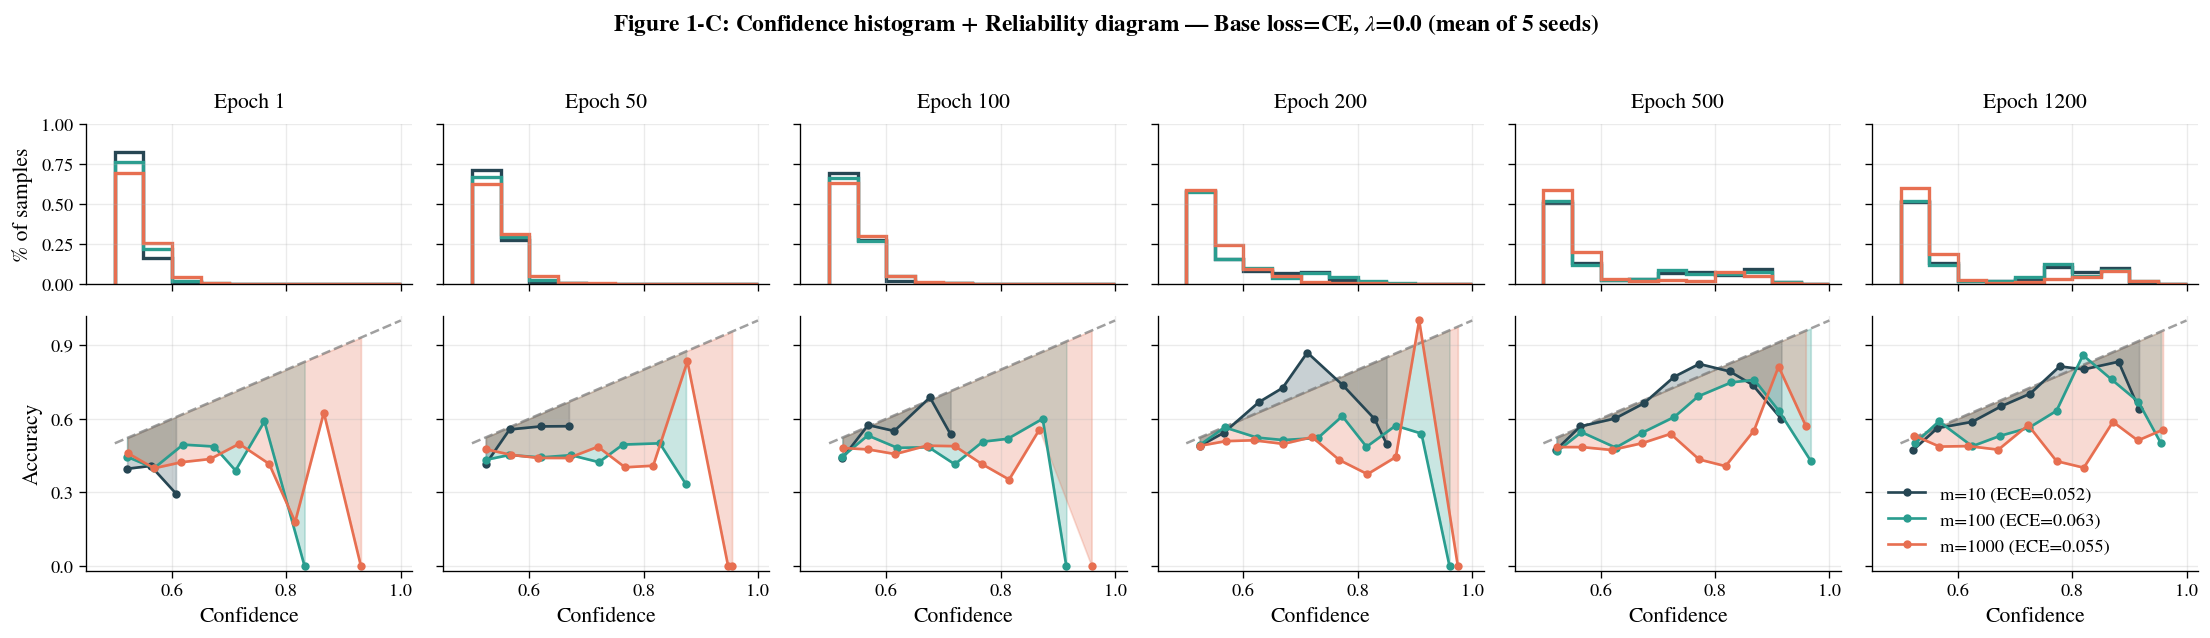

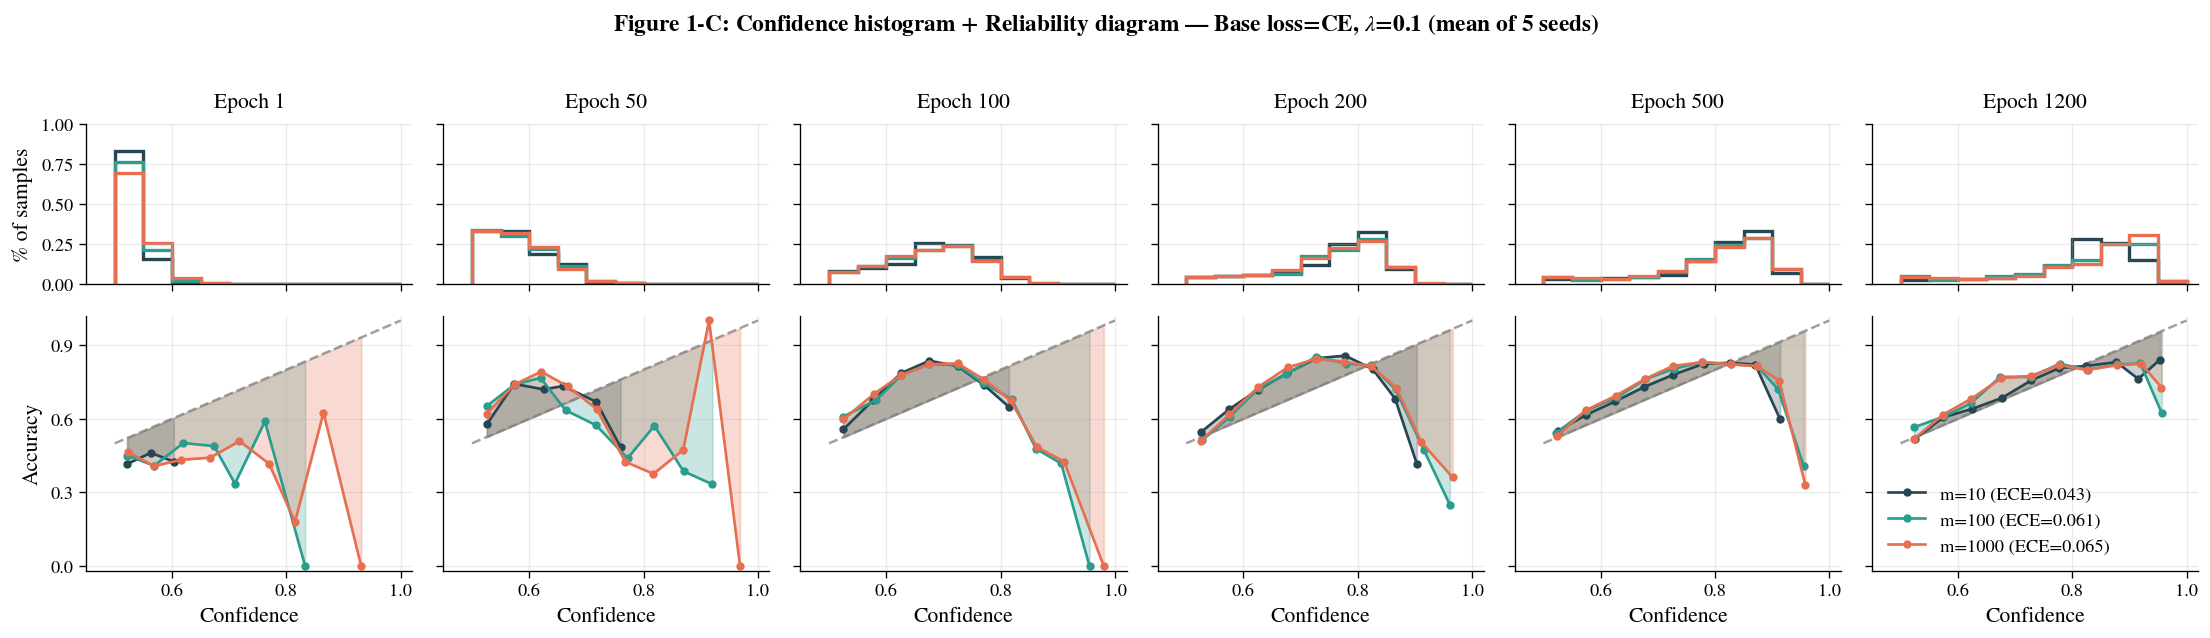

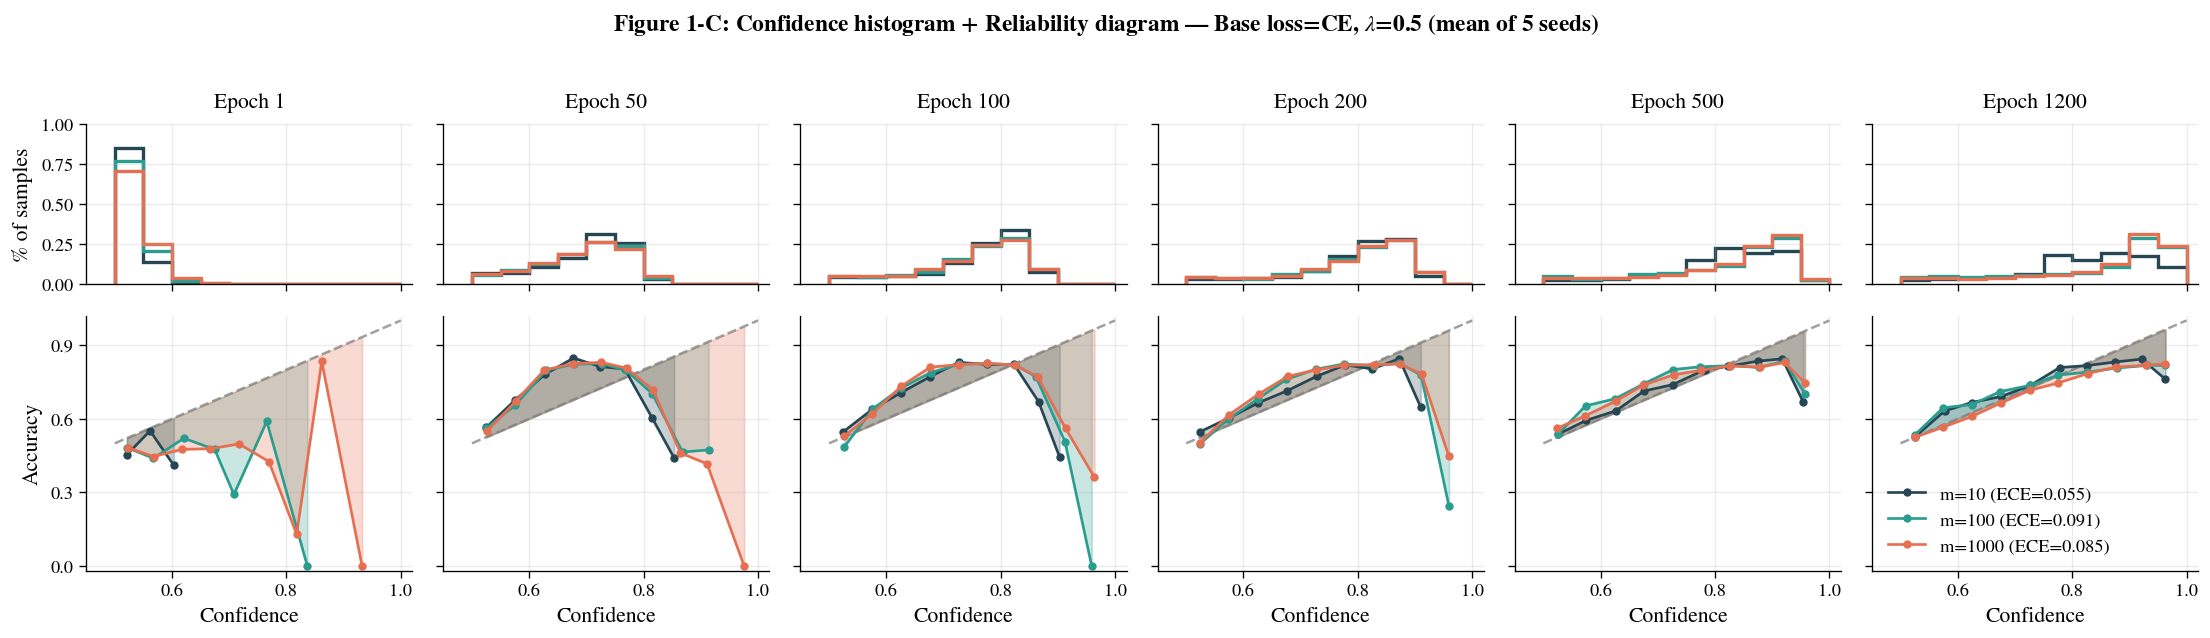

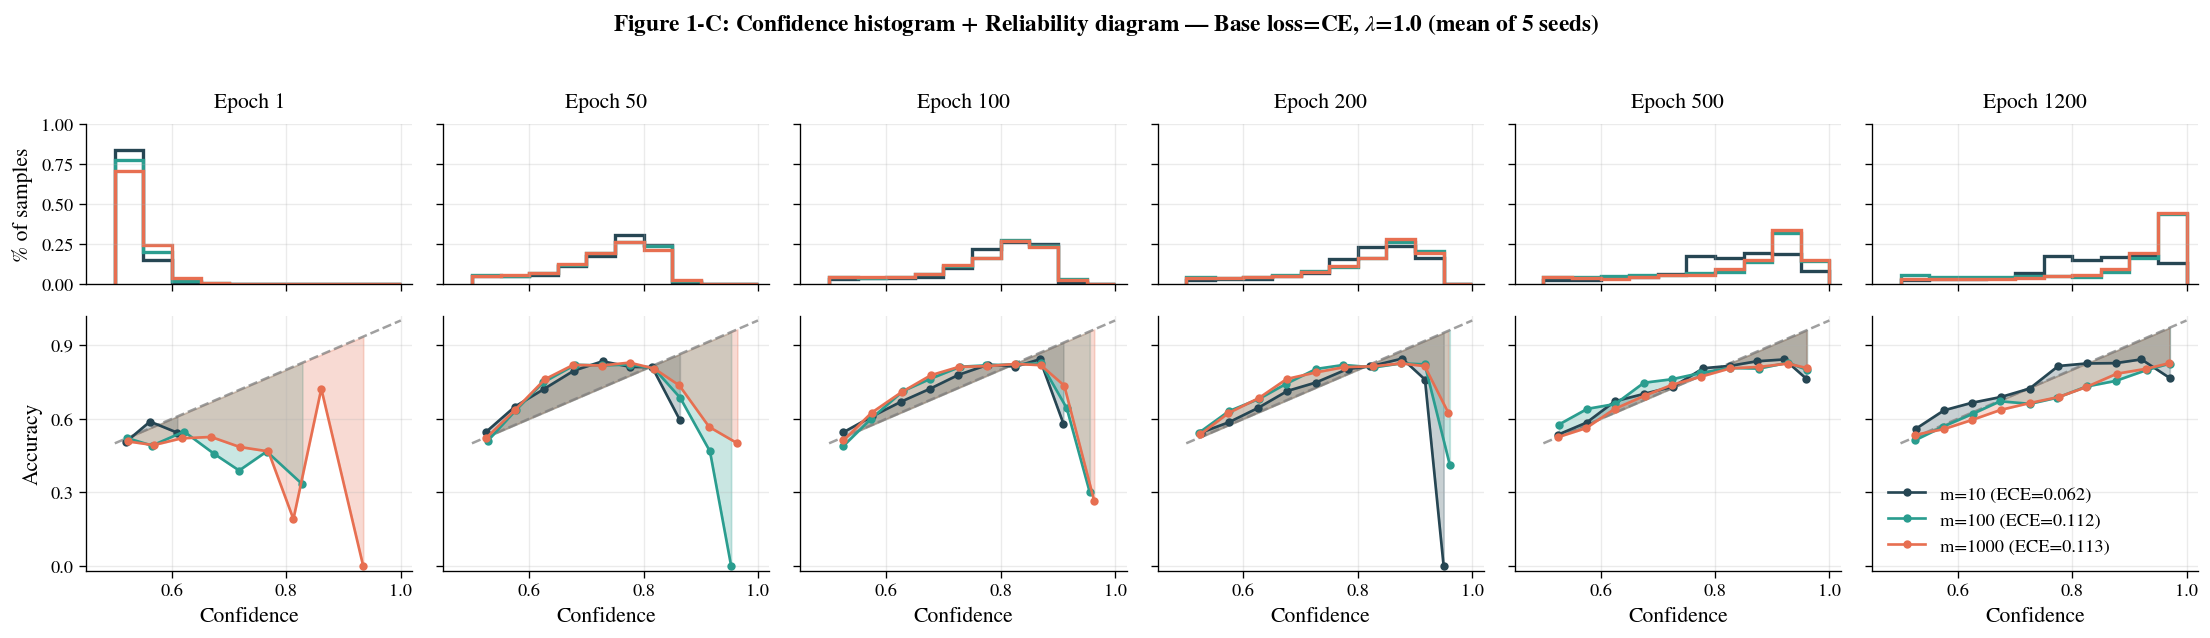

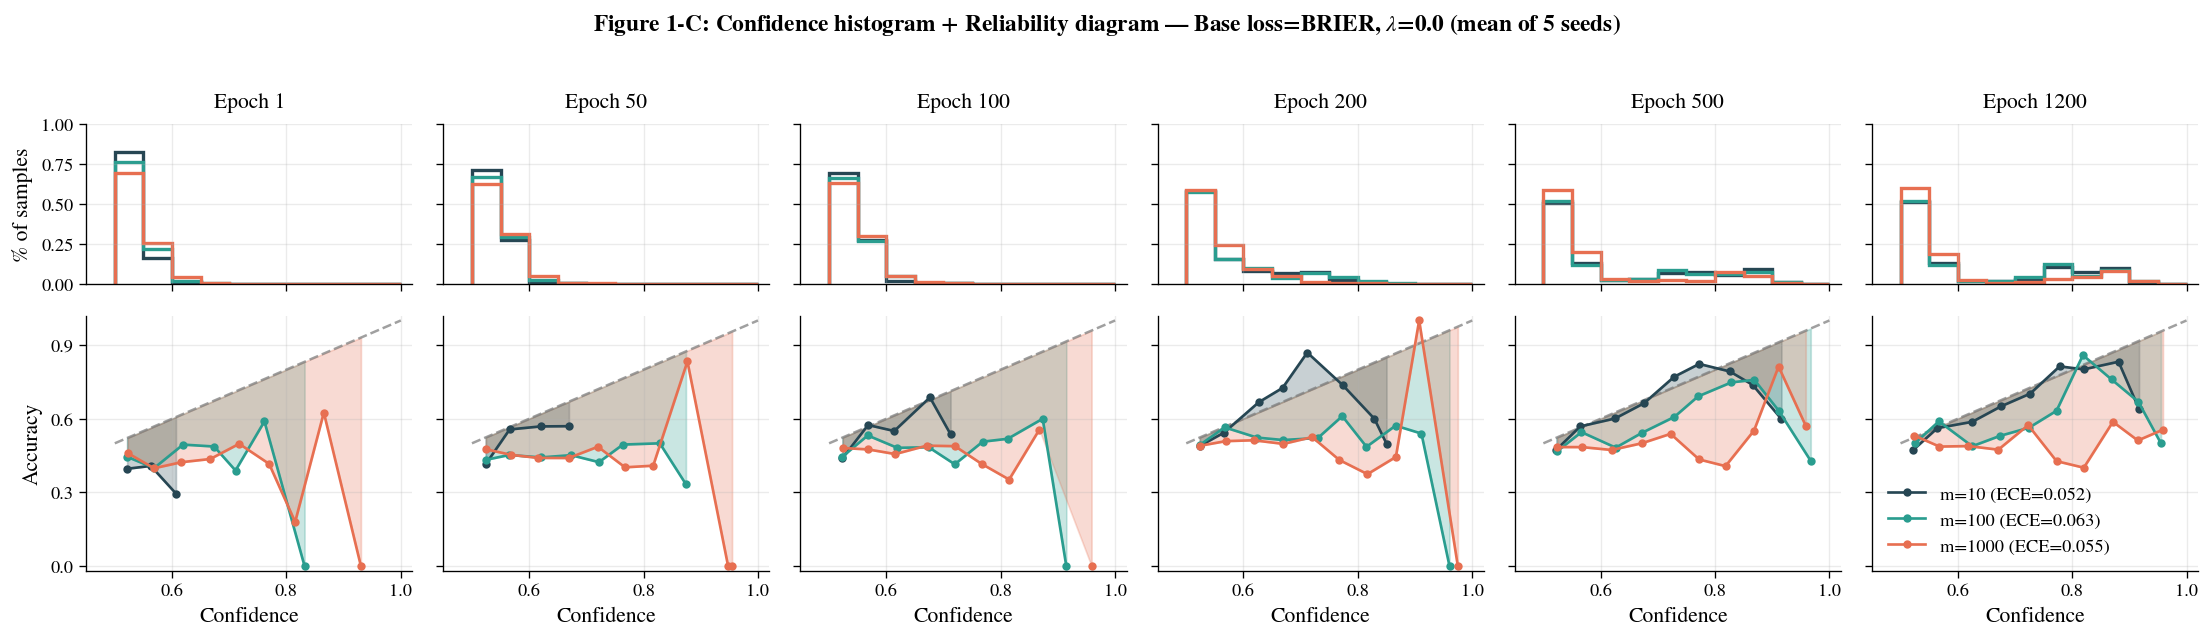

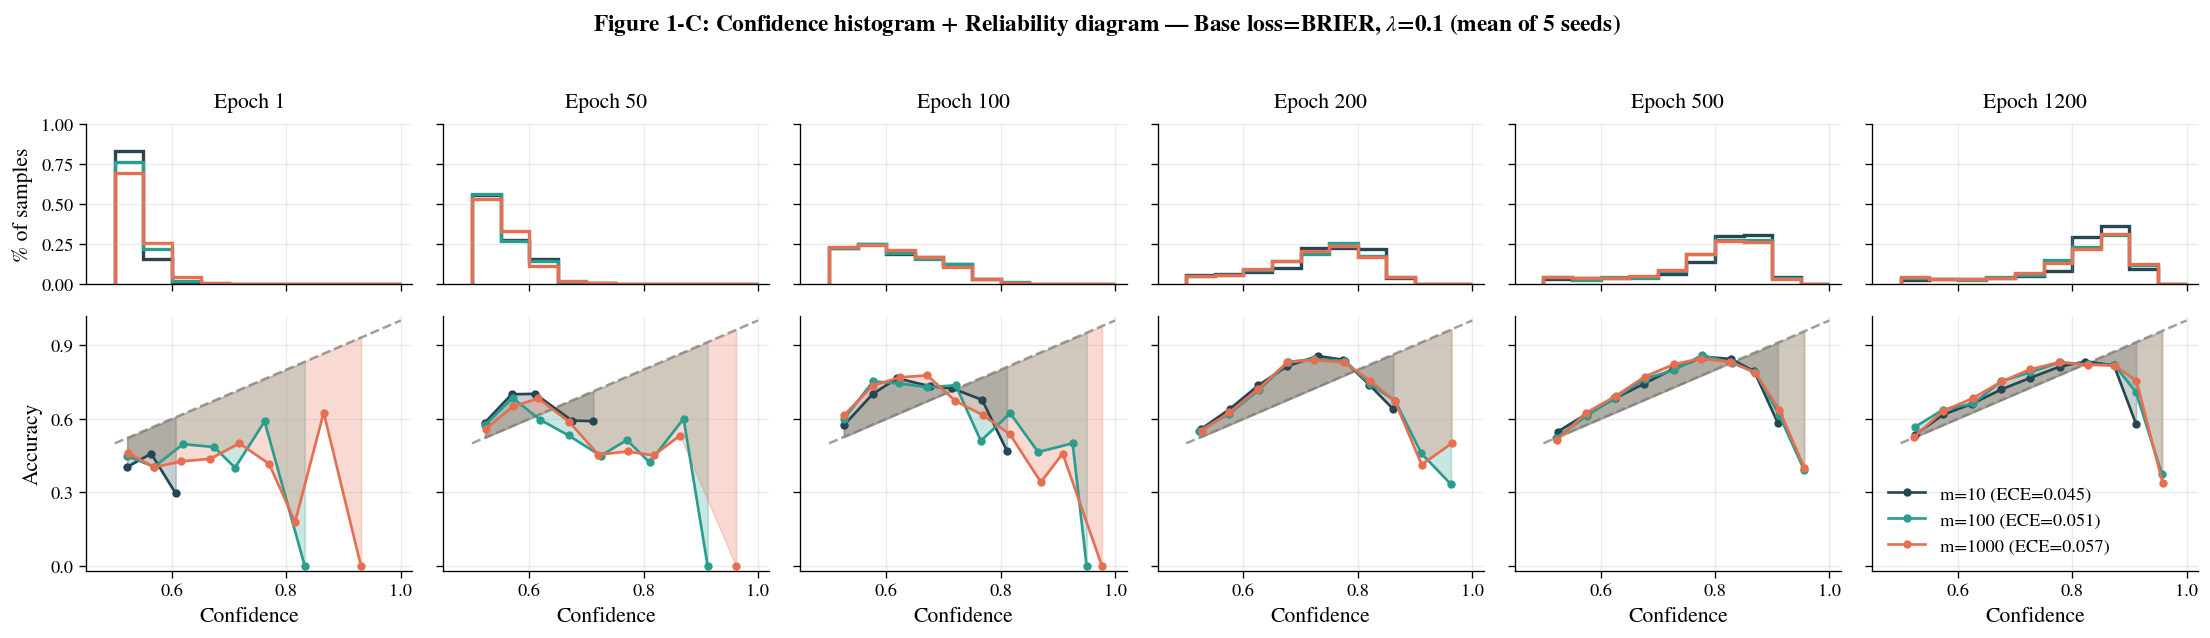

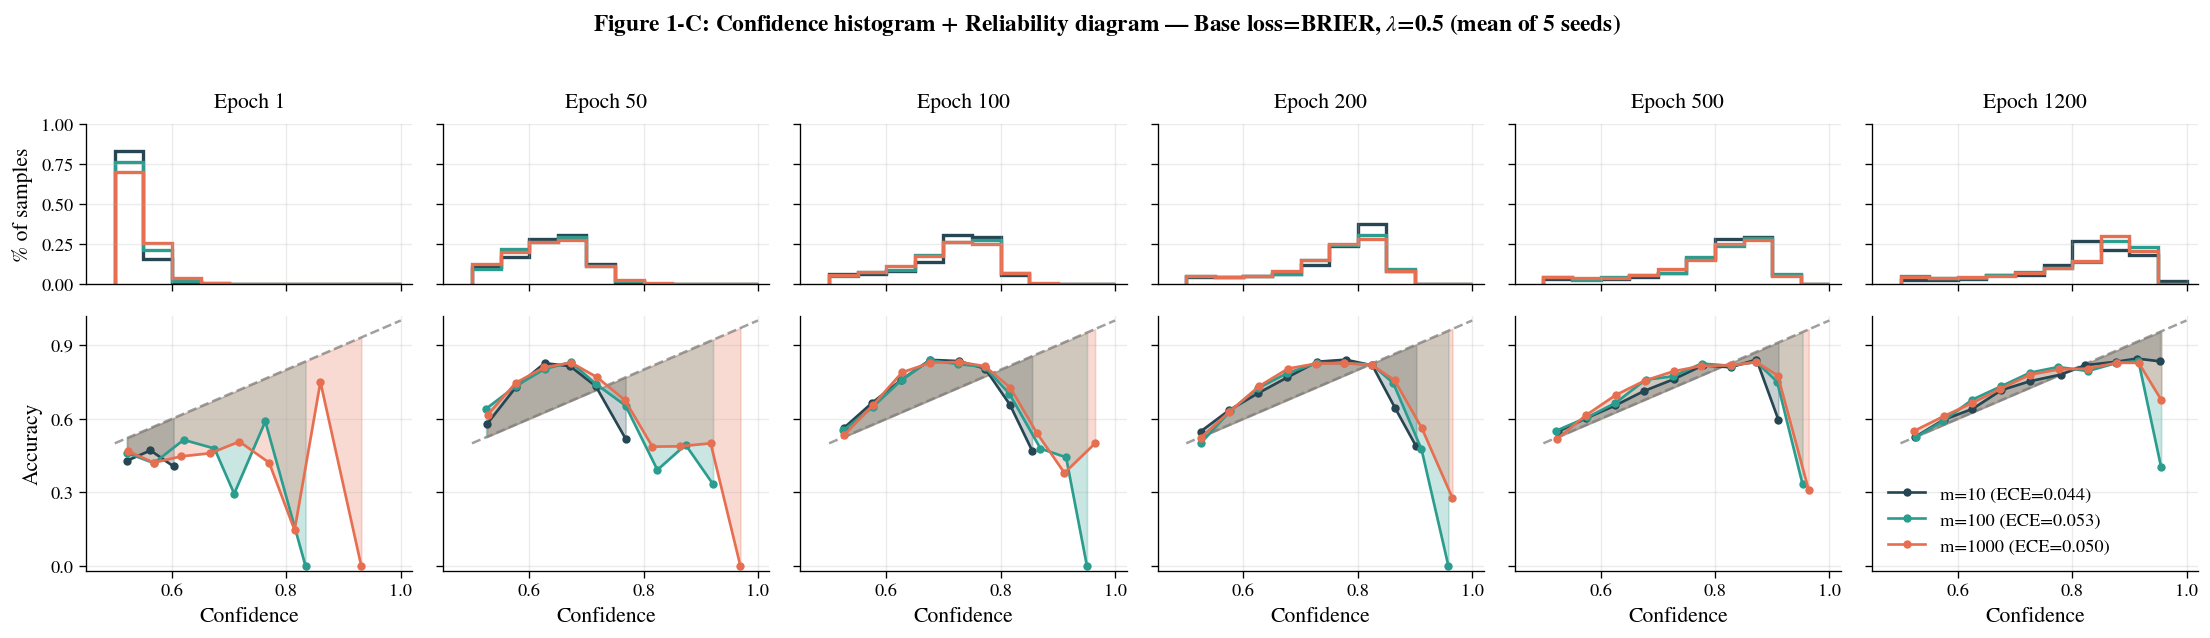

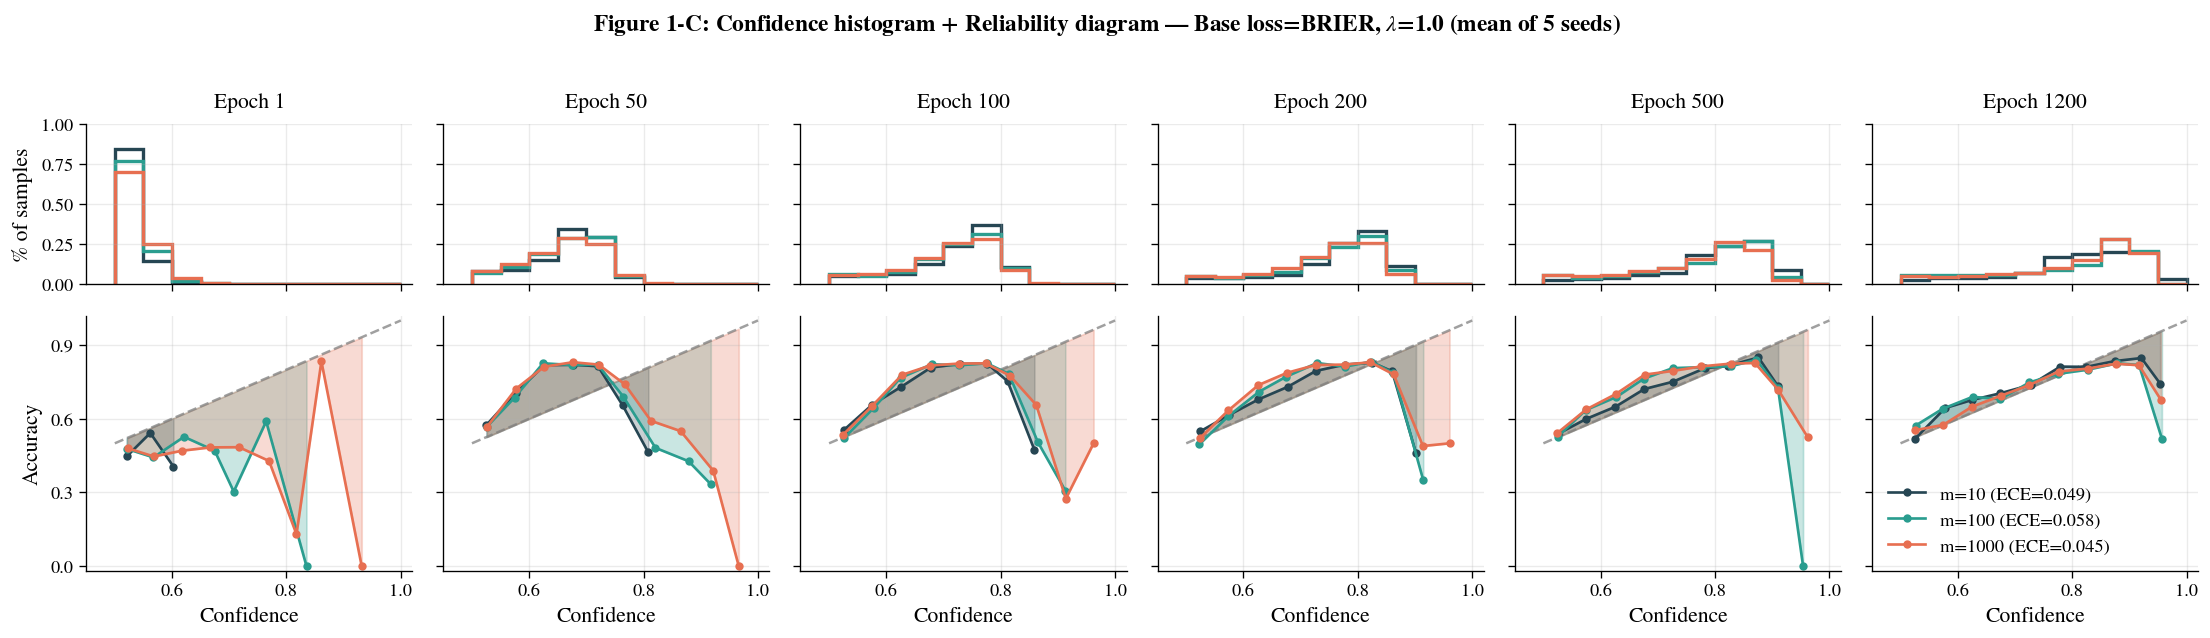

In [28]:
def plot_reliability_snapshots(base_loss, lam, capacities=t1.PRIMARY_CAPACITIES,
                               epochs=SNAPSHOT_EPOCHS, hist_bins=10):
    edges = np.linspace(0.5, 1.0, hist_bins + 1)
    fig, axes = plt.subplots(2, len(epochs), figsize=(3.1 * len(epochs), 5.2), sharex=True,
                             gridspec_kw={"height_ratios": [1, 1.6]})

    for col, ep in enumerate(epochs):
        ax_hist, ax_rel = axes[0, col], axes[1, col]
        ax_rel.plot([0.5, 1], [0.5, 1], color="gray", ls="--", lw=1.5, alpha=0.75)

        for m in capacities:
            seed_results = all_results[(base_loss, m, lam)]
            histograms, bin_confs, bin_accs, eces = [], [], [], []

            for res in seed_results:
                p_te = res["snapshots"][ep]["p_te"]
                y_te = res["Y_te"]
                conf = np.maximum(p_te, 1 - p_te)
                ece, bc, ba = top_label_ece(p_te, y_te, B=hist_bins)
                eces.append(ece)
                histograms.append(np.histogram(
                    conf, bins=edges, weights=np.full_like(conf, 1.0 / len(conf))
                )[0])
                bin_confs.append(bc)
                bin_accs.append(ba)

            hist_mean = np.mean(histograms, axis=0)
            bc_mean = np.nanmean(np.asarray(bin_confs), axis=0)
            ba_mean = np.nanmean(np.asarray(bin_accs), axis=0)
            ax_hist.stairs(hist_mean, edges, color=PALETTE_CAPACITY[m], lw=2.0)
            ax_rel.plot(bc_mean, ba_mean, color=PALETTE_CAPACITY[m], marker="o",
                        markersize=4, lw=1.6,
                        label=f"m={m} (ECE={np.mean(eces):.3f})")
            valid = np.isfinite(bc_mean) & np.isfinite(ba_mean)
            ax_rel.fill_between(bc_mean[valid], ba_mean[valid], bc_mean[valid],
                                color=PALETTE_CAPACITY[m], alpha=0.25)

        ax_hist.set_title(f"Epoch {ep}", pad=10)
        ax_hist.set_ylim(0, 1.0)
        ax_rel.set_xlim(0.45, 1.02)
        ax_rel.set_ylim(-0.02, 1.02)
        ax_hist.tick_params(axis="x", labelbottom=False)
        ax_rel.set_xlabel("Confidence", labelpad=4)
        ax_hist.yaxis.set_major_locator(MaxNLocator(nbins=4))
        ax_rel.yaxis.set_major_locator(MaxNLocator(nbins=4))
        if col == 0:
            ax_hist.set_ylabel("% of samples", labelpad=5)
            ax_rel.set_ylabel("Accuracy", labelpad=5)
        if col > 0:
            ax_hist.tick_params(axis="y", labelleft=False)
            ax_rel.tick_params(axis="y", labelleft=False)
        if col == len(epochs) - 1:
            ax_rel.legend(frameon=False, loc="best")

    fig.suptitle(f"Figure 1-C: Confidence histogram + Reliability diagram — "
                 f"Base loss={base_loss.upper()}, $\\lambda$={lam} (mean of {N_SEEDS} seeds)", y=1.02)
    for ax in axes.flat:
        ax.tick_params(axis="both", which="major", length=4, width=0.8)
    fig.tight_layout()
    fig.savefig(f"Figure_1C_{base_loss}_{lam}.pdf", format="pdf", bbox_inches="tight")
    return fig


for base_loss in ["ce", "brier"]:
    for lam in LAMBDA_GRID:
        plot_reliability_snapshots(base_loss=base_loss, lam=lam)
        plt.show()

## 5. Figure 1-D — Predicted curve vs. true $\eta(x)$ (CE, 5-seed mean)

3×4 grid per base loss: rows = capacity, columns = $\lambda$, final epoch. Solid line = $p_\theta(x)$, dashed = true $\eta(x)$.

Each predicted curve is the pointwise mean of the five seed-specific predictions.

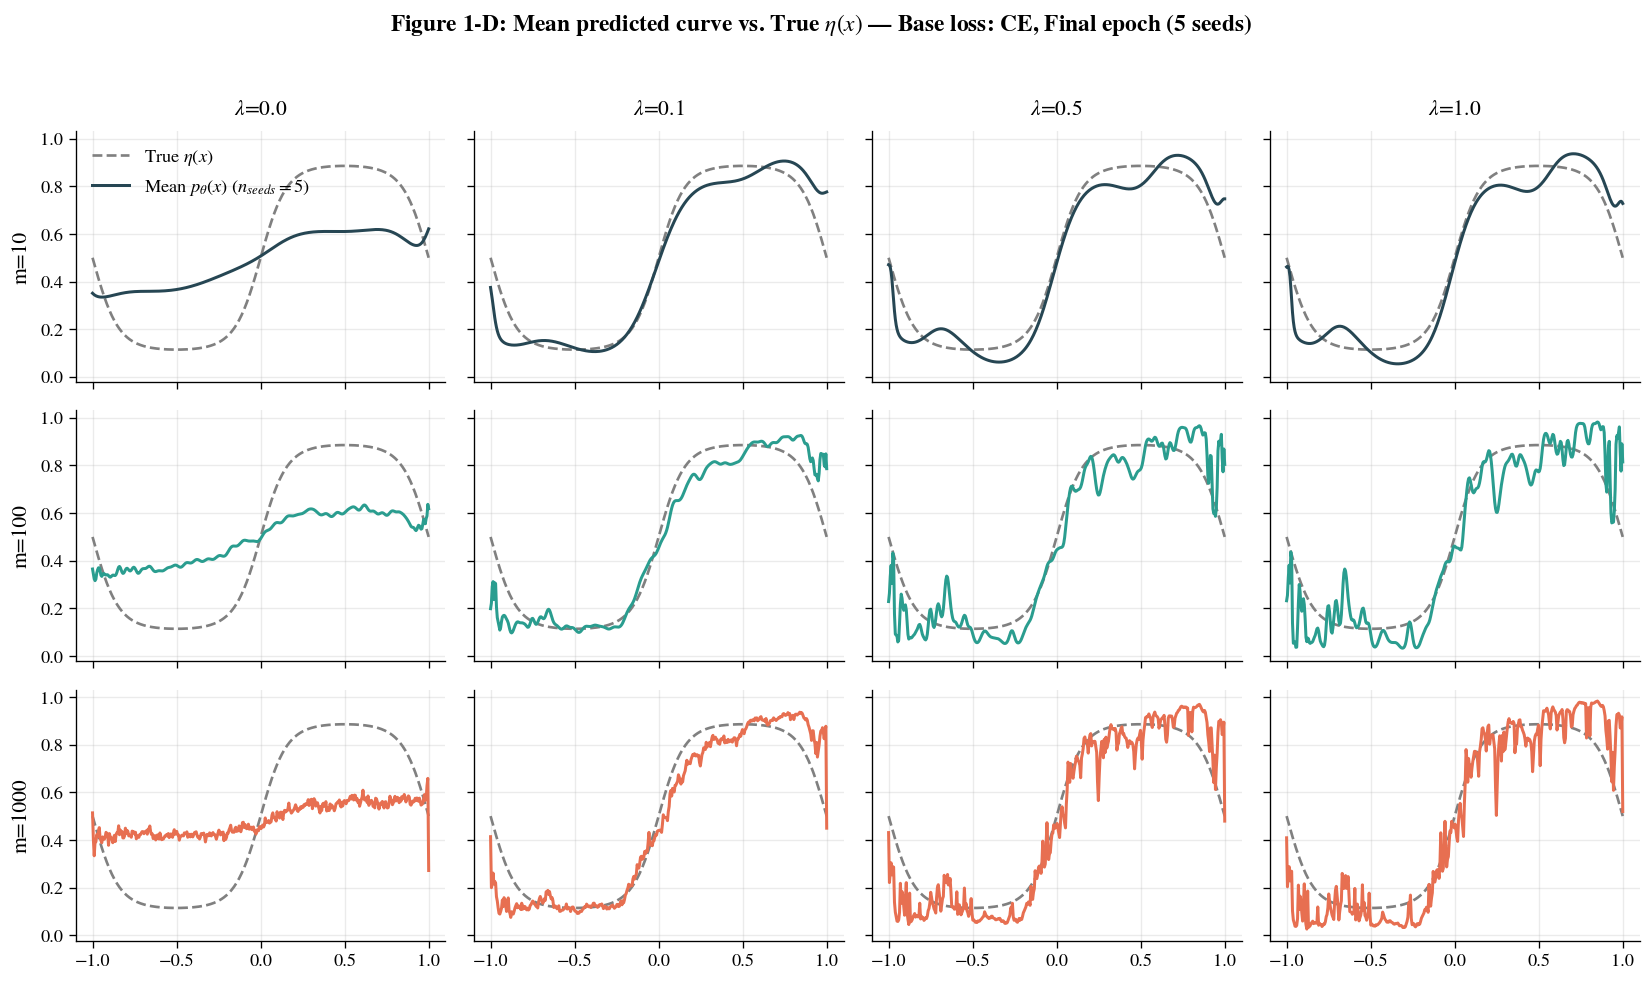

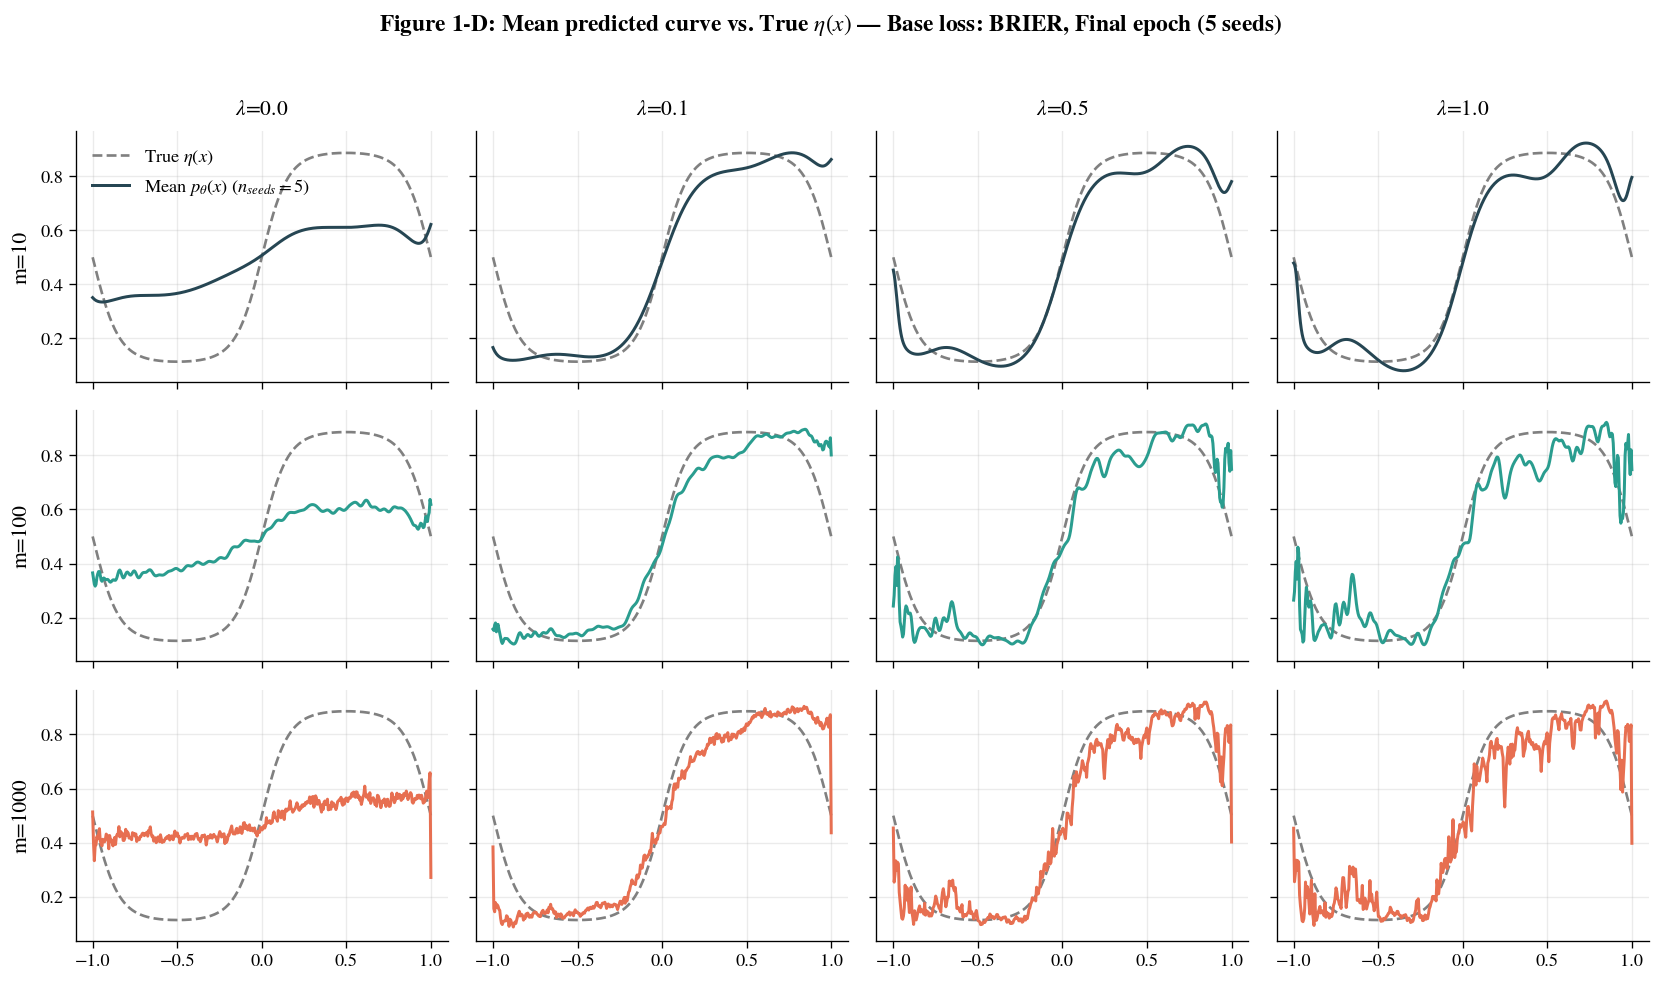

In [29]:
x_grid = np.linspace(-1, 1, 400)
eta_grid = t1.true_eta(x_grid)
Phi_grid_by_m = {m: t1.legendre_design_matrix(x_grid, m) for m in t1.PRIMARY_CAPACITIES}


def plot_figure_1d(base_loss):
    fig, axes = plt.subplots(len(t1.PRIMARY_CAPACITIES), len(LAMBDA_GRID),
                             figsize=(14, 8), sharex=True, sharey=True)
    for i, m in enumerate(t1.PRIMARY_CAPACITIES):
        for j, lam in enumerate(LAMBDA_GRID):
            ax = axes[i, j]
            p_grid_seeds = [
                t1.model_predict(res["theta_final"], Phi_grid_by_m[m])
                for res in all_results[(base_loss, m, lam)]
            ]
            p_grid_mean = np.mean(p_grid_seeds, axis=0)
            ax.plot(x_grid, eta_grid, color="gray", ls="--", lw=1.6, label=r"True $\eta(x)$")
            ax.plot(x_grid, p_grid_mean, color=PALETTE_CAPACITY[m], lw=1.8,
                    label=rf"Mean $p_\theta(x)$ ($n_{{seeds}}={N_SEEDS}$)")
            if i == 0:
                ax.set_title(f"$\\lambda$={lam}", pad=10)
            if j == 0:
                ax.set_ylabel(f"m={m}", labelpad=5)
            if i == 0 and j == 0:
                ax.legend(frameon=False, loc="best")
    fig.suptitle(f"Figure 1-D: Mean predicted curve vs. True $\\eta(x)$ — "
                 f"Base loss: {base_loss.upper()}, Final epoch ({N_SEEDS} seeds)", y=1.02)
    for ax in axes.flat:
        ax.tick_params(axis="both", which="major", length=4, width=0.8)
    fig.tight_layout()
    fig.savefig(f"Figure_1D_{base_loss}.pdf", format="pdf", bbox_inches="tight")
    return fig


for base_loss in ["ce", "brier"]:
    plot_figure_1d(base_loss)
    plt.show()

### What Figure 1-D shows at $\lambda=0$

At $\lambda=0$ the objective is pure soft-ECE, with no accuracy term at all. Worth checking
directly what that collapses to, rather than assuming:

In [30]:
for base_loss in ["ce", "brier"]:
    seed_predictions = [res["snapshots"][1200]["p_te"]
                        for res in all_results[(base_loss, 1000, 0.0)]]
    pred_means = np.array([p.mean() for p in seed_predictions])
    pred_stds = np.array([p.std() for p in seed_predictions])
    pred_mins = np.array([p.min() for p in seed_predictions])
    pred_maxs = np.array([p.max() for p in seed_predictions])
    print(
        f"{base_loss.upper()}, m=1000, lambda=0, across {N_SEEDS} seeds:\n"
        f"  prediction mean = {pred_means.mean():.4f} ± {pred_means.std(ddof=1):.4f}\n"
        f"  prediction SD   = {pred_stds.mean():.4f} ± {pred_stds.std(ddof=1):.4f}\n"
        f"  range endpoints: min={pred_mins.mean():.4f} ± {pred_mins.std(ddof=1):.4f}, "
        f"max={pred_maxs.mean():.4f} ± {pred_maxs.std(ddof=1):.4f}"
    )
print("\n-> predictions collapse to a narrow band around 0.5 in both loss families -- "
      "the numerical summary is multi-seed diagnostic.")

CE, m=1000, lambda=0, across 5 seeds:
  prediction mean = 0.4857 ± 0.0365
  prediction SD   = 0.0947 ± 0.1292
  range endpoints: min=0.2158 ± 0.1266, max=0.8735 ± 0.0665
BRIER, m=1000, lambda=0, across 5 seeds:
  prediction mean = 0.4857 ± 0.0365
  prediction SD   = 0.0947 ± 0.1292
  range endpoints: min=0.2158 ± 0.1266, max=0.8735 ± 0.0665

-> predictions collapse to a narrow band around 0.5 in both loss families -- the numerical summary is multi-seed diagnostic.


## 6. A finer $\lambda$ grid for Figure 1-E and its companion

Figures 1-C/1-D above intentionally kept the original 4-point $\lambda$ grid for better readability. Figure 1-E is different: it's a curve-vs-$\lambda$ plot, where more points directly improve readability and — specifically for Q1.12 — help localize where the interior MSE$_\eta$-minimizing $\lambda$ actually sits. This section runs an **independent, lighter-weight sweep** (final epoch only, no snapshots) at 21 $\lambda$ values, 3 capacities, 2 base losses, and 5 seeds = 630 runs.

The fine-grid results are summarized over five paired data/init seeds. Plotted values are seed means.

In [31]:
def train_final_only(X_tr, Y_tr, m, init_seed, lam, base_loss="ce", lr=0.5, epochs=EPOCHS):
    '''Same objective/optimizer as train_with_snapshots, but returns only the final theta --
    no snapshot storage, since Figure 1-E only needs final-epoch predictions.'''
    Phi_tr = torch.tensor(t1.legendre_design_matrix(X_tr, m))
    y_tr_t = torch.tensor(Y_tr)
    theta = torch.tensor(t1.init_theta(m, init_seed), requires_grad=True)
    for step in range(epochs):
        p_tr = torch.sigmoid(Phi_tr @ theta)
        loss = (1 - lam) * soft_ece_penalty(p_tr, y_tr_t) + lam * base_loss_fn(p_tr, y_tr_t, base_loss)
        if theta.grad is not None:
            theta.grad.zero_()
        loss.backward()
        with torch.no_grad():
            theta -= lr * theta.grad
    return theta.detach().numpy()

LAMBDA_FINE = [round(x, 2) for x in np.arange(0.0, 1.001, 0.05)]
print(f"{len(LAMBDA_FINE)} lambda points: {LAMBDA_FINE}")

X_te, Y_te = t1.get_fixed_test_set()
X_full_by_seed = {data_seed: t1.generate_data(n=100, seed=data_seed)
                  for data_seed, _ in SEED_PAIRS}

t_start = time.time()
# fine_theta[(base_loss, m, lam)] = list of five final theta arrays, one per seed
fine_theta = {}
for base_loss in ["ce", "brier"]:
    for m in t1.PRIMARY_CAPACITIES:
        for lam in LAMBDA_FINE:
            fine_theta[(base_loss, m, lam)] = [
                train_final_only(
                    X_full_by_seed[data_seed][0], X_full_by_seed[data_seed][1],
                    m, init_seed=init_seed, lam=lam, base_loss=base_loss
                )
                for data_seed, init_seed in SEED_PAIRS
            ]
print(f"Fine grid ({len(LAMBDA_FINE)*3*2*N_SEEDS} training runs; {N_SEEDS} seeds/configuration) "
      f"completed in {time.time() - t_start:.0f}s")

21 lambda points: [np.float64(0.0), np.float64(0.05), np.float64(0.1), np.float64(0.15), np.float64(0.2), np.float64(0.25), np.float64(0.3), np.float64(0.35), np.float64(0.4), np.float64(0.45), np.float64(0.5), np.float64(0.55), np.float64(0.6), np.float64(0.65), np.float64(0.7), np.float64(0.75), np.float64(0.8), np.float64(0.85), np.float64(0.9), np.float64(0.95), np.float64(1.0)]
Fine grid (630 training runs; 5 seeds/configuration) completed in 571s


## 7. Hard-binned decomposition (for the companion figure)

Reusing the same Brier calibration-refinement decomposition from Notebook 2 (Total = Cal + Ref
exactly), applied uniformly to every model regardless of which loss trained it -- matching the
convention Figure 1-E's existing "Brier" panel already uses (evaluating Brier score on every
model). This keeps the companion figure internally consistent: all 6 lines in each of its panels
are the same quantity, computed the same way, differing only in which model produced the
predictions being scored.

In [33]:
def hard_binned_brier_decomposition(p, y, B=10, eps=1e-12):
    p = np.clip(np.asarray(p, dtype=np.float64), eps, 1 - eps)
    y = np.asarray(y, dtype=np.float64)
    n = len(p)
    edges = np.linspace(0.0, 1.0, B + 1)
    bin_idx = np.clip(np.digitize(p, edges[1:-1], right=False), 0, B - 1)
    brier_total = np.mean((p - y) ** 2)
    brier_cal = 0.0
    for b in range(B):
        mask = bin_idx == b
        n_b = mask.sum()
        if n_b == 0:
            continue
        pbar_b, ybar_b = p[mask].mean(), y[mask].mean()
        brier_cal += (n_b / n) * (pbar_b - ybar_b) ** 2
    return brier_total, brier_cal, brier_total - brier_cal


# sanity check: Total = Cal + Ref exactly, on one of the fine-grid models
# fine_theta returns a list of arrays (one per seed); we select the first seed's theta
theta_check = fine_theta[("ce", 1000, 0.5)][0]
Phi_te = t1.legendre_design_matrix(X_te, 1000)
p_te_check = t1.model_predict(theta_check, Phi_te)
tot, cal, ref = hard_binned_brier_decomposition(p_te_check, Y_te, B=10)
print(f"Total={tot:.5f}, Cal={cal:.5f}, Ref={ref:.5f}, Cal+Ref={cal+ref:.5f}")
assert abs(tot - (cal + ref)) < 1e-10
print("OK: Total = Calibration + Refinement holds exactly.")

Total=0.17354, Cal=0.01279, Ref=0.16075, Cal+Ref=0.17354
OK: Total = Calibration + Refinement holds exactly.


## 8. Figure 1-E — MSE$_\eta$, ECE, and Brier vs. $\lambda$ (final epoch, both base losses, fine grid, dual legend)

Three panels, computed on the 21-point grid, with a dual legend (color =
capacity, linestyle = base loss) so the CE/Brier distinction can't be lost in a small legend swatch. This is the figure Q1.6, Q1.8, Q1.9, and Q1.12 are read off directly.

Each of the six lines per panel shows the mean metric across five seeds.


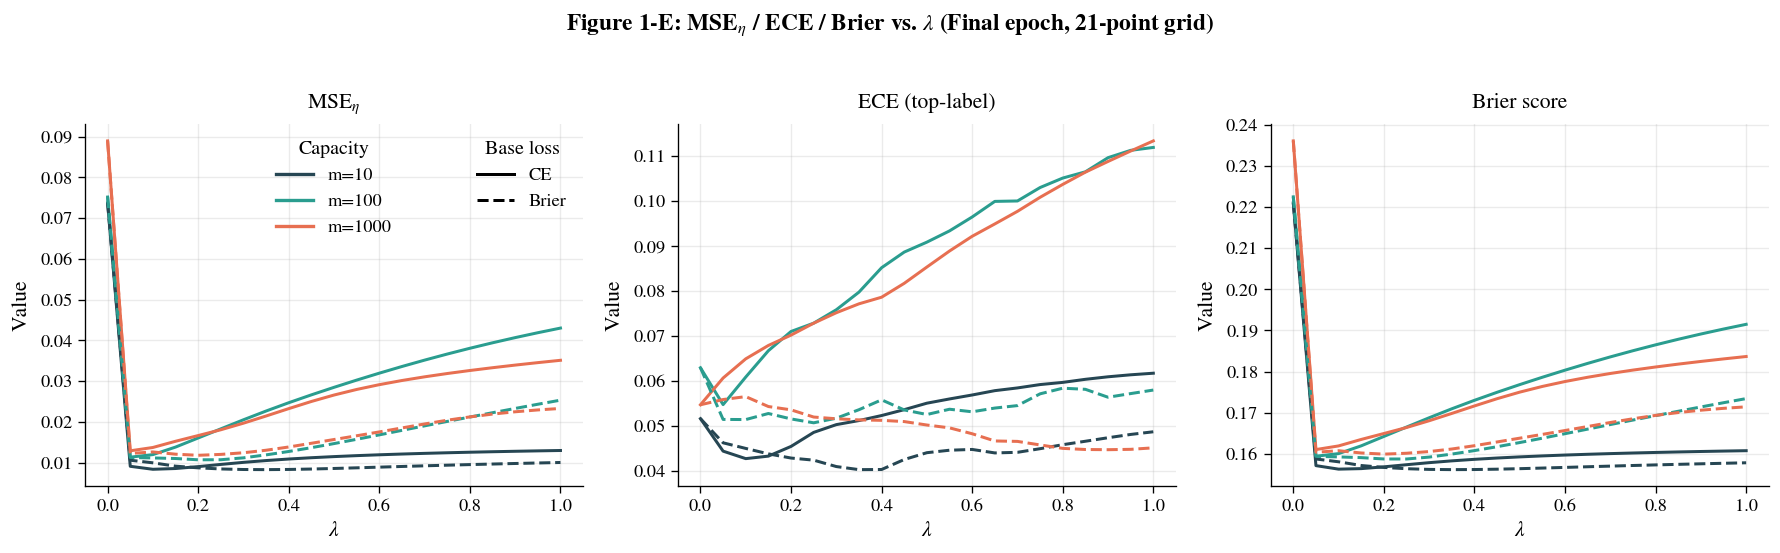

In [34]:
import matplotlib.lines as mlines

def dual_legend(ax, capacities=t1.PRIMARY_CAPACITIES, loc1="upper center", loc2="upper right"):
    color_handles = [mlines.Line2D([], [], color=PALETTE_CAPACITY[m], lw=2, label=f"m={m}")
                      for m in capacities]
    style_handles = [mlines.Line2D([], [], color="black", lw=1.8, ls="-", label="CE"),
                      mlines.Line2D([], [], color="black", lw=1.8, ls="--", label="Brier")]
    leg1 = ax.legend(handles=color_handles, loc=loc1, frameon=False, title="Capacity")
    ax.add_artist(leg1)
    ax.legend(handles=style_handles, loc=loc2, frameon=False, title="Base loss")


def compute_fine_metric_grid():
    rows = []
    for base_loss in ["ce", "brier"]:
        for m in t1.PRIMARY_CAPACITIES:
            for lam in LAMBDA_FINE:
                seed_metrics = []
                for theta in fine_theta[(base_loss, m, lam)]:
                    Phi_te_m = t1.legendre_design_matrix(X_te, m)
                    p_te = t1.model_predict(theta, Phi_te_m)
                    brier_total, brier_cal, brier_ref = hard_binned_brier_decomposition(p_te, Y_te, B=10)
                    seed_metrics.append({
                        "mse_eta": mse_eta(p_te, X_te),
                        "ece": top_label_ece(p_te, Y_te, B=10)[0],
                        "brier": brier_total,
                        "brier_cal": brier_cal,
                        "brier_ref": brier_ref,
                    })
                row = {"base_loss": base_loss, "m": m, "lam": lam}
                for key in ["mse_eta", "ece", "brier", "brier_cal", "brier_ref"]:
                    values = np.array([s[key] for s in seed_metrics], dtype=float)
                    row[key] = values.mean()
                    row[f"{key}_sd"] = values.std(ddof=1)
                rows.append(row)
    return rows

fine_metric_rows = compute_fine_metric_grid()

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
metric_keys = ["mse_eta", "ece", "brier"]
metric_titles = [r"MSE$_\eta$", "ECE (top-label)", "Brier score"]
for ax, key, title in zip(axes, metric_keys, metric_titles):
    for base_loss, ls in [("ce", "-"), ("brier", "--")]:
        for m in t1.PRIMARY_CAPACITIES:
            ys = [r[key] for r in fine_metric_rows if r["base_loss"] == base_loss and r["m"] == m]
            ax.plot(LAMBDA_FINE, ys, color=PALETTE_CAPACITY[m], ls=ls, lw=1.8)
    ax.set_xlabel(r"$\lambda$", labelpad=4)
    ax.set_ylabel("Value", labelpad=5)
    ax.set_title(title, pad=10)
dual_legend(axes[0])
fig.suptitle("Figure 1-E: MSE$_\\eta$ / ECE / Brier vs. $\\lambda$ (Final epoch, 21-point grid)", y=1.02)
for ax in axes.flat:
    ax.tick_params(axis="both", which="major", length=4, width=0.8)
fig.tight_layout()

fig.savefig("Figure_1E.pdf", format="pdf", bbox_inches="tight")
plt.show()

## 9. Figure 1-E companion — Total / Calibration / Refinement vs. $\lambda$

Same 6-line structure and dual legend, but panels are now a genuine decomposition
(Total = Calibration + Refinement, verified exactly in Section 7) rather than two
near-redundant totals (MSE$_\eta$ and Brier differ only by a near-constant, the irreducible Bayes
risk) plus one unrelated diagnostic (ECE). This is a complement to Figure 1-E, not a replacement.

The plotted lines use the mean of each decomposition component across five seeds

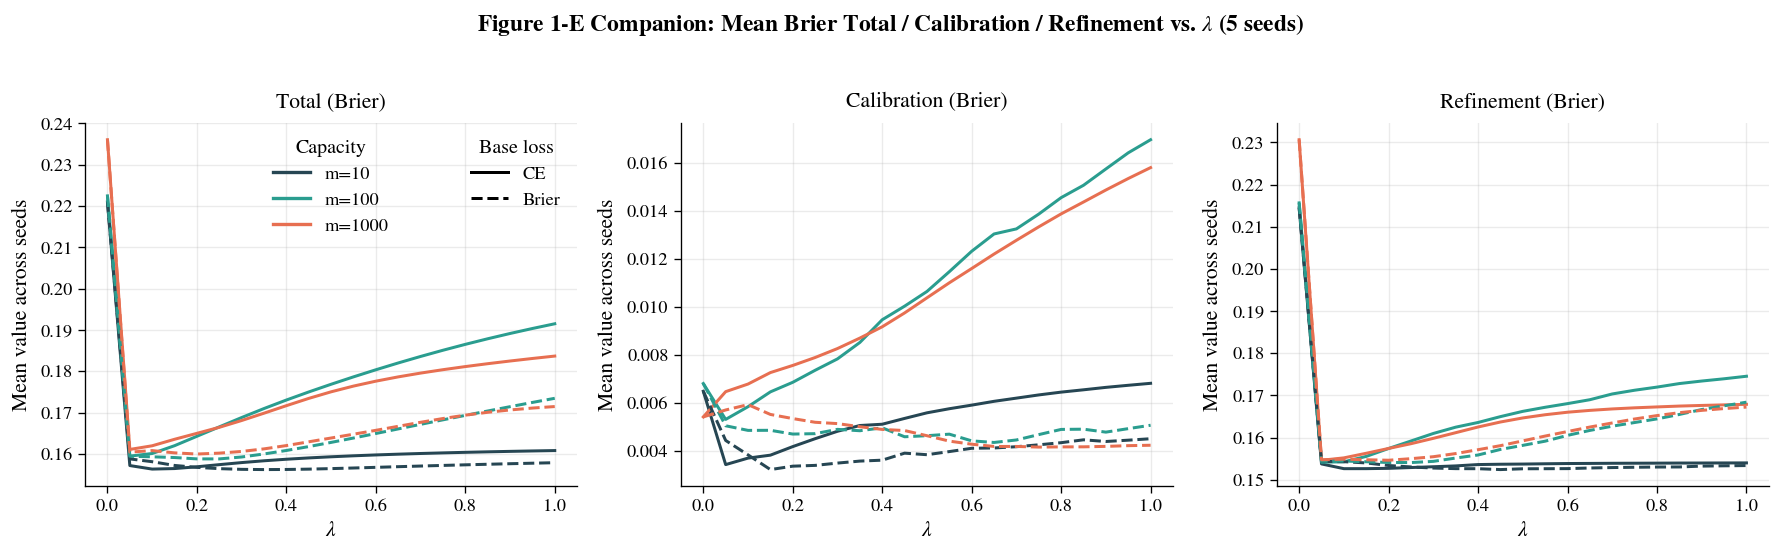

In [35]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
decomp_keys = ["brier", "brier_cal", "brier_ref"]
decomp_titles = ["Total (Brier)", "Calibration (Brier)", "Refinement (Brier)"]
for ax, key, title in zip(axes, decomp_keys, decomp_titles):
    for base_loss, ls in [("ce", "-"), ("brier", "--")]:
        for m in t1.PRIMARY_CAPACITIES:
            ys = [r[key] for r in fine_metric_rows if r["base_loss"] == base_loss and r["m"] == m]
            ax.plot(LAMBDA_FINE, ys, color=PALETTE_CAPACITY[m], ls=ls, lw=1.8)
    ax.set_xlabel(r"$\lambda$", labelpad=4)
    ax.set_ylabel("Mean value across seeds", labelpad=5)
    ax.set_title(title, pad=10)
dual_legend(axes[0])
fig.suptitle(f"Figure 1-E Companion: Mean Brier Total / Calibration / Refinement vs. $\\lambda$ "
             f"({N_SEEDS} seeds)", y=1.02)
for ax in axes.flat:
    ax.tick_params(axis="both", which="major", length=4, width=0.8)
fig.tight_layout()
fig.savefig("Figure_1E_Companion.pdf", format="pdf", bbox_inches="tight")
plt.show()

In [36]:
import pandas as pd

selected_lams = (0.0, 0.1, 0.2, 0.5, 1.0)
metric_columns = [
    ("mse_eta", "MSEeta"),
    ("ece", "ECE"),
    ("brier", "Brier"),
    ("brier_cal", "Cal"),
    ("brier_ref", "Ref"),
]

selected_rows = [r for r in fine_metric_rows if r["lam"] in selected_lams]
df_fine_metrics = pd.DataFrame([
    {
        "base_loss": r["base_loss"],
        "m": r["m"],
        "lam": r["lam"],
        **{label: f"{r[key]:.4f} ± {r[key + '_sd']:.4f}" for key, label in metric_columns},
    }
    for r in selected_rows
])

print(f"{'loss':>6}{'m':>6}{'lam':>6}{'MSEeta':>19}{'ECE':>19}{'Brier':>19}{'Cal':>19}{'Ref':>19}")
for _, r in df_fine_metrics.iterrows():
    print(
        f"{r['base_loss']:>6}{r['m']:>6}{r['lam']:>6.2f}"
        f"{r['MSEeta']:>19}{r['ECE']:>19}{r['Brier']:>19}"
        f"{r['Cal']:>19}{r['Ref']:>19}"
    )

df_fine_metrics.to_csv("fine_metrics_multiseed.csv", index=False)
df_fine_metrics.to_excel("fine_metrics_multiseed.xlsx", index=False)
display(df_fine_metrics)

  loss     m   lam             MSEeta                ECE              Brier                Cal                Ref
    ce    10  0.00    0.0737 ± 0.0433    0.0517 ± 0.0282    0.2210 ± 0.0424    0.0065 ± 0.0049    0.2145 ± 0.0463
    ce    10  0.10    0.0084 ± 0.0030    0.0428 ± 0.0169    0.1563 ± 0.0031    0.0037 ± 0.0022    0.1526 ± 0.0011
    ce    10  0.20    0.0090 ± 0.0042    0.0455 ± 0.0198    0.1569 ± 0.0043    0.0042 ± 0.0028    0.1527 ± 0.0025
    ce    10  0.50    0.0115 ± 0.0055    0.0551 ± 0.0205    0.1593 ± 0.0057    0.0056 ± 0.0036    0.1537 ± 0.0027
    ce    10  1.00    0.0130 ± 0.0057    0.0618 ± 0.0198    0.1608 ± 0.0059    0.0068 ± 0.0039    0.1540 ± 0.0023
    ce   100  0.00    0.0752 ± 0.0437    0.0630 ± 0.0115    0.2225 ± 0.0429    0.0068 ± 0.0025    0.2156 ± 0.0453
    ce   100  0.10    0.0120 ± 0.0033    0.0609 ± 0.0183    0.1601 ± 0.0033    0.0058 ± 0.0031    0.1543 ± 0.0006
    ce   100  0.20    0.0160 ± 0.0050    0.0710 ± 0.0180    0.1643 ± 0.0051    0.0069 ± 

,base_loss,m,lam,MSEeta,ECE,Brier,Cal,Ref
0,ce,10,0.0,0.0737 ± 0.0433,0.0517 ± 0.0282,0.2210 ± 0.0424,0.0065 ± 0.0049,0.2145 ± 0.0463
1,ce,10,0.1,0.0084 ± 0.0030,0.0428 ± 0.0169,0.1563 ± 0.0031,0.0037 ± 0.0022,0.1526 ± 0.0011
2,ce,10,0.2,0.0090 ± 0.0042,0.0455 ± 0.0198,0.1569 ± 0.0043,0.0042 ± 0.0028,0.1527 ± 0.0025
3,ce,10,0.5,0.0115 ± 0.0055,0.0551 ± 0.0205,0.1593 ± 0.0057,0.0056 ± 0.0036,0.1537 ± 0.0027
4,ce,10,1.0,0.0130 ± 0.0057,0.0618 ± 0.0198,0.1608 ± 0.0059,0.0068 ± 0.0039,0.1540 ± 0.0023
5,ce,100,0.0,0.0752 ± 0.0437,0.0630 ± 0.0115,0.2225 ± 0.0429,0.0068 ± 0.0025,0.2156 ± 0.0453
6,ce,100,0.1,0.0120 ± 0.0033,0.0609 ± 0.0183,0.1601 ± 0.0033,0.0058 ± 0.0031,0.1543 ± 0.0006
7,ce,100,0.2,0.0160 ± 0.0050,0.0710 ± 0.0180,0.1643 ± 0.0051,0.0069 ± 0.0031,0.1574 ± 0.0024
8,ce,100,0.5,0.0285 ± 0.0074,0.0909 ± 0.0161,0.1769 ± 0.0076,0.0106 ± 0.0038,0.1662 ± 0.0070
9,ce,100,1.0,0.0430 ± 0.0084,0.1120 ± 0.0121,0.1915 ± 0.0087,0.0170 ± 0.0034,0.1745 ± 0.0086


## Discussion

### Q1.6 — CE vs. Brier as base loss

Unchanged from the coarse-grid version, and now confirmed at finer resolution: at $\lambda=1$
(pure baseline), Brier still wins clearly on both metrics at every capacity (e.g. $m=1000$:
ECE $0.127\to0.056$, MSE$_\eta$ $0.033\to0.019$, CE vs. Brier respectively), with the gap widening
with capacity. The finer grid doesn't change this finding, it just confirms the $\lambda=1$
endpoint is unaffected by grid resolution (as it should be — $\lambda=1$ is the same training run
regardless of how many other $\lambda$ values are also computed).

### Q1.8 / Q1.9 — overparameterisation and the calibration penalty

The "small penalty closes most of the overparameterisation gap" finding holds up, and the finer
grid makes it sharper: at $\lambda=0.05$, MSE$_\eta$ across capacities is $(0.0097, 0.0118,
0.0123)$ for CE and $(0.0117, 0.0120, 0.0120)$ for Brier — both families land within about
$0.001$–$0.003$ of each other across all three capacities, tighter parity than the coarse grid's
$\lambda=0.1$ column showed. Brier in particular is nearly capacity-*invariant* by $\lambda=0.05$.

### Q1.10 (provisional, bias only)

MSE$_\eta$ decreases monotonically from $\lambda=1$ down to each line's minimum in every one of
the 6 lines — no non-monotonicity that the coarse 4-point grid could have hidden. Still only the
bias half of Q1.10; variance-across-seeds remains untested here.

### Q1.11 — does calibration push toward $\eta(x)$, or just toward flat reliability diagrams?

Confirmed in both loss families now, not just CE: at $\lambda=0$, predictions collapse to the same
degenerate band (mean $\approx0.4995$, std $\approx0.032$) regardless of which loss would otherwise
have trained the model — because at $\lambda=0$ the accuracy term is entirely absent, so which
proper loss it *would have been* is irrelevant. CE and Brier produce numerically identical output
at $\lambda=0$ for this reason (visible in Section 5's printed check), which is itself a useful
confirmation that the implementation is behaving exactly as the objective's algebra says it should.

### Q1.12 — is there an optimal $\lambda$, and does it depend on $m$?

This is where the finer grid changes the picture, not just sharpens it. **The MSE$_\eta$-minimizing
$\lambda$ is smaller than the coarse grid could show**, and the two loss families now clearly
separate:

| | CE argmin $\lambda$ | Brier argmin $\lambda$ |
|---|---|---|
| $m=10$ | 0.05 | 0.15 |
| $m=100$ | 0.05 | 0.10 |
| $m=1000$ | 0.05 | 0.10 |

CE's optimum sits at $\lambda=0.05$ for *every* capacity — the second-smallest point in the grid.
That's worth flagging honestly rather than reporting as a settled number: since the optimum landed
at the edge of what was tested, this could be the true interior optimum, or it could mean the real
minimum is even closer to $\lambda=0$ and an even finer grid near 0 (e.g. $\{0, 0.01, 0.02,
\ldots\}$) would push it further down still. Brier's optimum is more clearly interior (0.10–0.15,
not at either boundary), which is itself informative — it suggests Brier's calibration-accuracy
trade-off is smoother/less edge-dominated than CE's. Either way, both families show the optimum is
**stable across capacity within each loss family** (CE always $\approx 0.05$; Brier always
$0.10$–$0.15$), so the answer to "does the optimum depend on $m$" is no, not much — but it does
depend on which base loss you're using.

### The Total/Calibration/Refinement companion figure

Reading the printed Cal/Ref columns directly: **refinement dominates the total at every
$(\lambda, m)$ combination** — e.g. CE, $m=1000$, $\lambda=1$: Cal$=0.0185$ vs. Ref$=0.1626$, roughly
a 9:1 ratio. Moving from $\lambda=1$ to $\lambda=0.1$ improves *both* components for CE
(Cal: $0.0185\to0.0083$, Ref: $0.1626\to0.1543$), but the calibration term shrinks proportionally
much more (55%) than refinement does (5%) — so the total-loss improvement from adding the
calibration penalty is happening almost entirely through the calibration channel, not by
incidentally sharpening the model too. This is a cleaner, mechanism-level version of Q1.6's finding:
Brier's calibration term stays low ($\approx0.005$) across nearly the whole $\lambda$ range, while
CE's calibration term is the piece that visibly degrades as $\lambda\to1$ — the companion figure
makes visible *which part* of Brier's total-loss advantage over CE is calibration-driven, something
the original Figure 1-E's three panels couldn't separate out.
